# DDM-HMM states on the neuromodulator sessions

What are the collaborator's DDM-HMM states? This notebook characterises them, as a first step before mapping them onto the trial modes of `1_trial_modes.ipynb`.

**Data**: `neuromodulators/pose_qc_hmm_k4/` exports the session store of [davcrom/ibl_neuromodulators](https://github.com/davcrom/ibl_neuromodulators). It is loaded through `Functions/ddm_hmm.py`, which reads with the archive's own `h5_loaders.py` and puts both fit formats on IBL conventions. Its docstring gives the parameter meanings and both formats.

**Model**: each mouse has its own fit, pooling all of its sessions, so **state numbers mean nothing across mice**. Every state is a DDM with these parameters:
- bound `B`;
- drift gain `k`, with drift = k · contrast^α;
- starting point `a0`, as a fraction of the bound (0.5 = unbiased);
- non-decision time `tau`.

`alpha` is shared across states. The states are linked by a trial-to-trial Markov chain. The new-format fits add an *omission* state, which turns out to be exactly the no-go trials (checked below), so it is dropped from everything after that.

**Fit caveats**:
- Two formats. ZFM-08776 and ZFM-06271 carry the collaborator's first-round (legacy) fits. These have no omission state, lack some trials, use MAP rather than Viterbi states, have tau fixed at 0, and come with almost no run summary.
- `converged=False` everywhere. Every new-format fit stopped at its 1000-iteration EM cap rather than at its tolerance. The parameters may still have been drifting slightly; it does not mean the fit is bad. The repo keeps the best of several restarts.
- Only K = 4 is in the export. The collaborator's importer stores every K that was fitted, so other K exist upstream.

In [1]:
import sys, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

REPO = pathlib.Path.cwd().resolve()
while not (REPO / 'Functions' / 'ddm_hmm.py').exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
sys.path.insert(0, str(REPO / 'paper-individuality'))
from Functions import ddm_hmm as dh
import paper_style as ps
ps.use('paper')

K = 4
print('K available in the archive:', dh.available_k())
trials, params = dh.load_all(K)
print(f"{len(trials):,} fitted trials, {trials['eid'].nunique()} sessions, {trials['subject'].nunique()} mice")

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi
K available in the archive: [4]


191,150 fitted trials, 240 sessions, 8 mice


## Sanity checks and the fits at a glance

In [2]:
print(dh.check_fit_tables(trials, params))
# the omission state is exactly the no-go trials
print(pd.crosstab(trials['state'], trials['choice'] == 0, colnames=['no-go']))

fits = (params.drop_duplicates('subject').set_index('subject')
        [['format', 'converged', 'iterations', 'n_sessions_fit', 'n_trials_fit']])
fits['sessions_here'] = trials.groupby('subject')['eid'].nunique()
fits['trials_here'] = trials.groupby('subject').size()
fits['NM'] = trials.groupby('subject')['target_NM'].agg(lambda x: ', '.join(sorted(set(x))))
fits['alpha'] = params.groupby('subject')['alpha'].first().round(2)
fits

{'p_sum_range': (np.float64(0.9999999999999883), np.float64(1.0000000000000107)), 'median_posterior_of_assigned_state': 0.9227083362083428, 'mice': 8}
no-go  False  True 
state              
1      40610      0
2      76090      0
3      43133      0
4      30892      0
5          0    425


,format,converged,iterations,n_sessions_fit,n_trials_fit,sessions_here,trials_here,NM,alpha
subject,,,,,,,,,
ZFM-09439,new,False,1000.0,51.0,44476,41,35738,DR-5HT,0.53
ZFM-09365,new,False,1000.0,46.0,32896,43,30334,DR-5HT,0.45
ZFM-04019,new,False,1000.0,53.0,35985,20,14612,SNc-DA,0.16
ZFM-08871,new,False,1000.0,36.0,30143,35,29148,LC-NE,0.48
ZFM-09394,new,False,1000.0,50.0,42426,46,39158,VTA-DA,0.40
ZFM-08818,new,False,1000.0,36.0,31789,21,18748,VTA-DA,0.28
ZFM-08776,legacy,NaN,NaN,NaN,24390,33,22910,LC-NE,0.48
ZFM-06271,legacy,NaN,NaN,NaN,1606,1,502,LC-NE,0.14


ZFM-06271 has a single session (~500 trials), so it is kept in the tables but left out of the figures (`MICE`). The fits also pool more sessions than the export holds (`n_sessions_fit` vs `sessions_here`), because the export keeps only sessions that pass photometry and pose QC.

How crisp are the states? Below is the posterior of the most likely state on each trial.

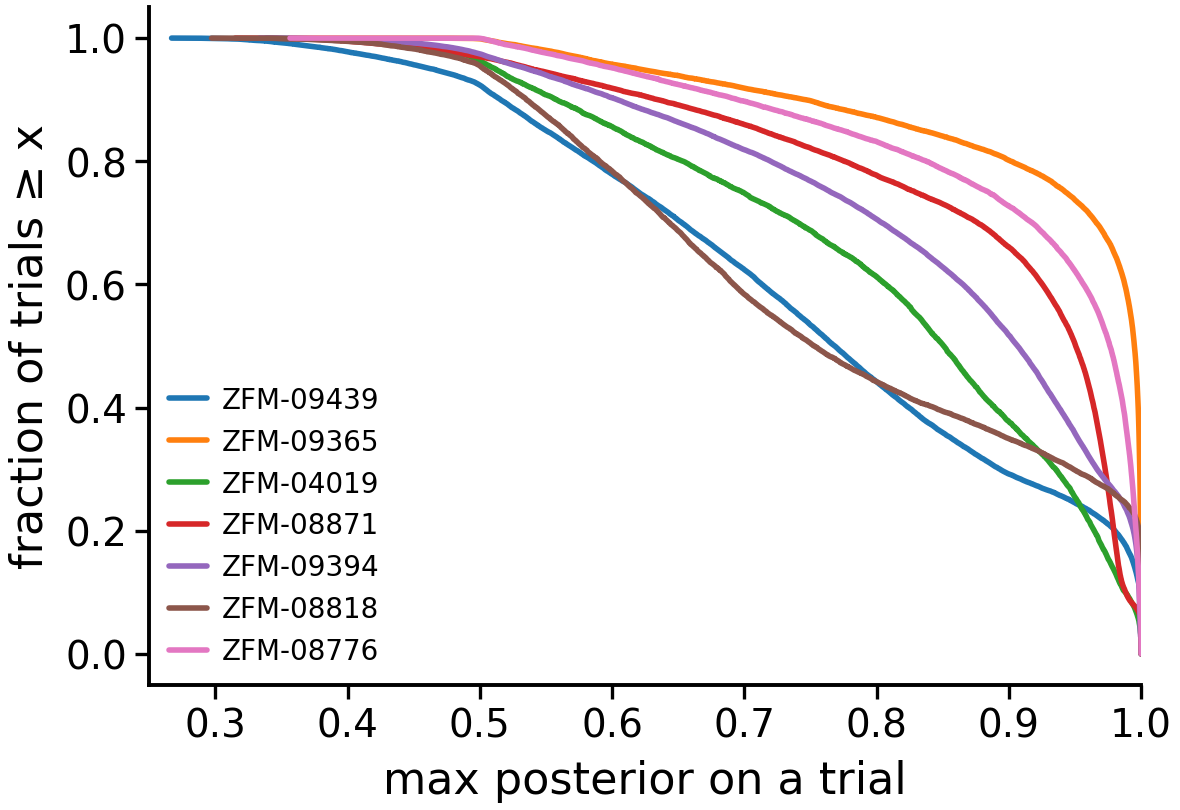

fraction of trials with max posterior > 0.8, per mouse:
{'ZFM-04019': 0.61, 'ZFM-06271': 0.45, 'ZFM-08776': 0.83, 'ZFM-08818': 0.44, 'ZFM-08871': 0.78, 'ZFM-09365': 0.87, 'ZFM-09394': 0.71, 'ZFM-09439': 0.44}


In [3]:
MICE = fits.index[fits['sessions_here'] >= 5].tolist()
p_cols = [c for c in trials.columns if c.startswith('p_state_')]
trials['p_max'] = trials[p_cols].max(axis=1)

fig, ax = plt.subplots(figsize=(3.2, 2.2))
for m in MICE:
    x = np.sort(trials.loc[trials['subject'] == m, 'p_max'])
    ax.plot(x, 1 - np.arange(len(x)) / len(x), lw=1, label=m)
ax.set(xlabel='max posterior on a trial', ylabel='fraction of trials ≥ x', xlim=(0.25, 1))
ax.legend(fontsize=5, frameon=False)
plt.show()
print('fraction of trials with max posterior > 0.8, per mouse:')
print(trials.groupby('subject')['p_max'].apply(lambda x: (x > 0.8).mean()).round(2).to_dict())

## One row per (mouse, state): behaviour and parameters

From here on, only go trials in DDM states are used. All task variables come from the IBL trials table:
- `acc_easy`: accuracy at contrasts of 25% and above;
- `acc_hard`: accuracy at 6.25–12.5%;
- `p_right_0`: P(right choice) at 0% contrast;
- `block_shift`: P(right) in 0.2 blocks minus P(right) in 0.8 blocks, at contrasts of 12.5% and below;
- `rt`: response − stimOnTrigger, the RT the DDM models;
- `rt_move`: first movement − stimOnTrigger;
- `trial_frac`: mean position in the session (0 = start, 1 = end);
- `run_median`: median length of a Viterbi run within a session;
- `dwell_expected` = 1 / (1 − self-transition);
- `occ_0.2 − occ_0.8`: occupancy in right-likely blocks minus left-likely blocks.

In [4]:
d = trials[~trials['is_omission'] & (trials['choice'] != 0)].copy()

def state_stats(g):
    low = g[g['contrast'] <= 12.5]
    return pd.Series({
        'n': len(g),
        'acc_easy': g.loc[g['contrast'] >= 25, 'correct'].mean(),
        'acc_hard': g.loc[(g['contrast'] > 0) & (g['contrast'] <= 12.5), 'correct'].mean(),
        'p_right_0': g.loc[g['contrast'] == 0, 'choice_right'].mean(),
        'block_shift': (low.loc[low['probabilityLeft'] == 0.2, 'choice_right'].mean()
                        - low.loc[low['probabilityLeft'] == 0.8, 'choice_right'].mean()),
        'rt_median': g['rt'].median(),
        'rt_move_median': g['rt_move'].median(),
        'trial_frac': g['trial_frac'].mean(),
    })

def run_lengths(g):
    v = g['state'].to_numpy()
    starts = np.r_[0, np.flatnonzero(np.diff(v)) + 1]
    return pd.DataFrame({'state': v[starts], 'length': np.diff(np.r_[starts, len(v)])})

runs = (d.groupby(['subject', 'eid'])[['state']].apply(run_lengths)
        .reset_index(level=[0, 1]).reset_index(drop=True))

S = d.groupby(['subject', 'state']).apply(state_stats, include_groups=False).reset_index()
S['occupancy'] = S['n'] / S.groupby('subject')['n'].transform('sum')
S = S.merge(runs.groupby(['subject', 'state'])['length'].median().rename('run_median').reset_index(),
            on=['subject', 'state'])
blk = d[d['probabilityLeft'] != 0.5].groupby(['subject', 'probabilityLeft'])['state'].value_counts(normalize=True).unstack(1)
S = S.merge((blk[0.2] - blk[0.8]).rename('occ_0.2 − occ_0.8').reset_index(), on=['subject', 'state'], how='left')
S = S.merge(params.loc[params['kind'] == 'ddm', ['subject', 'state', 'B', 'k', 'a0', 'tau', 'self_trans']],
            on=['subject', 'state'])
S['dwell_expected'] = 1 / (1 - S['self_trans'])

r = np.corrcoef(S['a0'], S['p_right_0'])[0, 1]
print(f'a0 vs P(right | 0% contrast) across all states: r = {r:.2f}  ->  a0 > 0.5 = biased to the RIGHT choice')

a0 vs P(right | 0% contrast) across all states: r = 0.92  ->  a0 > 0.5 = biased to the RIGHT choice


### A provisional naming of states across mice

The same few kinds of state recur in every mouse. Each state is named by these rules, applied in order:
1. **disengaged**: `k` < 0.3. The stimulus barely drives the choice: RTs of 2–7 s, accuracy near chance, often stuck on one side, and they come late in the session.
2. **biased-R / biased-L**: `a0` is more than 0.2 from 0.5. The starting point sits close to one bound.
3. **engaged**: easy-trial accuracy ≥ 0.9 *and* median RT < 0.8 s.
4. **slow**: median RT ≥ 0.8 s. These are deliberate states: shallower but structured psychometrics, bell-shaped chronometrics, and they grow late in the session.
5. **impulsive**: everything else. Fast (median RT ~0.2–0.4 s), but with errors on easy trials.

The thresholds were set by eye on this table, as a starting vocabulary. They are not a classifier. They live in `Functions/ddm_hmm.py` (`name_state`), so this notebook and the mapping notebook share them.

In [5]:
# the rules and thresholds live in Functions/ddm_hmm.py (name_state), shared with 3_ddm_hmm_trial_modes.ipynb
from Functions.ddm_hmm import K_DISENGAGED, A0_BIAS, ACC_ENGAGED, RT_SLOW, LABEL_COLORS, name_state

S['label'] = S.apply(name_state, axis=1)
S['tag'] = 's' + S['state'].astype(str) + ' ' + S['label']

show = ['subject', 'state', 'label', 'occupancy', 'acc_easy', 'acc_hard', 'p_right_0', 'block_shift',
        'occ_0.2 − occ_0.8', 'rt_median', 'rt_move_median', 'trial_frac', 'run_median', 'dwell_expected',
        'B', 'k', 'a0', 'tau']
(S[show].style.format(precision=2).format({'state': '{:d}'})
 .background_gradient(subset=['acc_easy'], cmap='Blues', vmin=0.5, vmax=1)
 .background_gradient(subset=['p_right_0', 'a0'], cmap='PuOr', vmin=0, vmax=1)
 .background_gradient(subset=['rt_median'], cmap='Greys', vmin=0, vmax=3))

,subject,state,label,occupancy,acc_easy,acc_hard,p_right_0,block_shift,occ_0.2 − occ_0.8,rt_median,rt_move_median,trial_frac,run_median,dwell_expected,B,k,a0,tau
0,ZFM-04019,1,engaged,0.399055,1.000000,1.000000,0.629630,0.551933,-0.015890,0.479700,0.303537,0.530888,2.000000,2.133812,4.940304,6.054516,0.533790,0.000000
1,ZFM-04019,2,engaged,0.295189,0.953820,0.822335,0.656467,0.563301,0.097893,0.450200,0.278639,0.385050,26.000000,14.171195,2.024568,1.898544,0.561634,0.000000
2,ZFM-04019,3,disengaged,0.037542,0.719424,0.471761,0.900000,0.025095,-0.014049,7.515950,5.408419,0.794568,3.000000,2.857353,8.512992,0.078059,0.801089,0.000000
3,ZFM-04019,4,slow,0.268215,0.751678,0.537299,0.666667,0.335304,-0.067954,1.712600,1.223574,0.512872,1.000000,1.912052,2.962514,0.382892,0.617526,0.000000
4,ZFM-06271,1,disengaged,0.139442,0.645161,0.400000,1.000000,-0.095395,0.077851,2.840900,1.550093,0.536943,3.500000,6.730404,4.420280,0.116869,0.701639,0.000000
5,ZFM-06271,2,biased-L,0.235060,0.717949,0.698113,0.038462,-0.078431,-0.185347,1.347850,0.814593,0.477538,2.000000,2.662374,3.522254,0.305825,0.229171,0.000000
6,ZFM-06271,3,engaged,0.527888,1.000000,1.000000,0.725000,0.624081,-0.003835,0.574400,0.411093,0.479218,2.000000,2.008511,4.297109,5.385344,0.542744,0.000000
7,ZFM-06271,4,biased-R,0.097610,0.500000,0.538462,1.000000,0.375000,0.111331,1.139200,0.735092,0.490052,1.000000,1.969689,2.917472,0.405191,0.731737,0.000000
8,ZFM-08776,1,engaged,0.616194,0.905692,0.762624,0.611258,0.502408,0.009420,0.399100,0.277471,0.385839,9.000000,11.421251,1.352213,2.815392,0.543806,0.000000
9,ZFM-08776,2,disengaged,0.154387,0.645833,0.550704,0.255539,0.128396,-0.020542,3.102300,2.620365,0.809840,13.000000,29.427223,3.846803,0.215853,0.375937,0.000000


In [6]:
print(pd.crosstab(S['subject'], S['label']).loc[:, list(LABEL_COLORS)])

label      engaged  slow  impulsive  biased-L  biased-R  disengaged
subject                                                            
ZFM-04019        2     1          0         0         0           1
ZFM-06271        1     0          0         1         1           1
ZFM-08776        1     1          1         0         0           1
ZFM-08818        1     0          1         0         1           1
ZFM-08871        0     0          1         1         1           1
ZFM-09365        2     1          0         0         0           1
ZFM-09394        1     1          0         1         0           1
ZFM-09439        2     0          1         0         0           1


### The states in parameter space and in behaviour space

The left panel shows the DDM parameters; marker size is occupancy. The middle panel shows what the states *do*. The right panel checks the sign of `a0` against the 0%-contrast choices, which is how the naming reads `a0` as left or right.

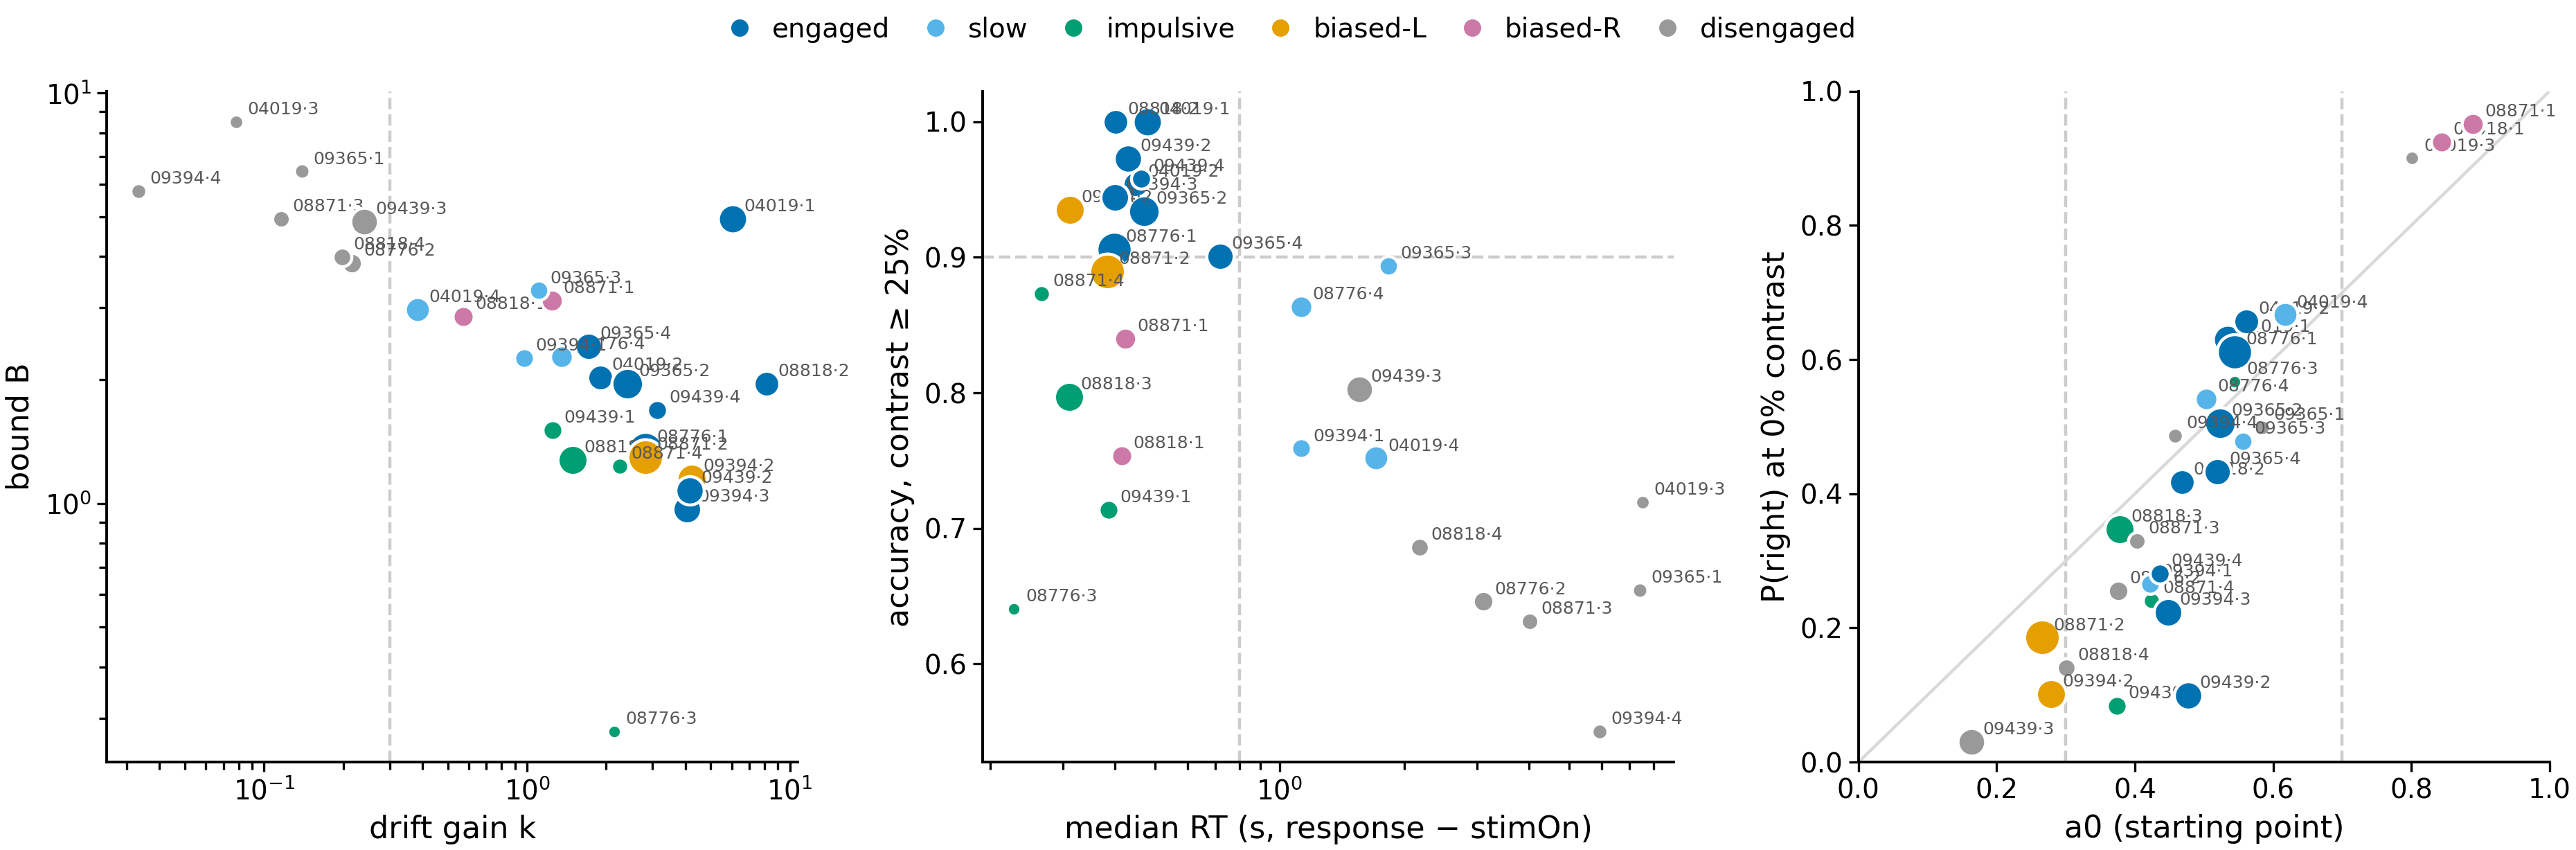

In [7]:
Sm = S[S['subject'].isin(MICE)]
fig, axes = plt.subplots(1, 3, figsize=(9.5, 3))
for _, r in Sm.iterrows():
    c = LABEL_COLORS[r['label']]
    sz = 10 + 120 * r['occupancy']
    short = r['subject'].removeprefix('ZFM-') + f"·{r['state']}"
    for ax, (x, y) in zip(axes, [(r['k'], r['B']), (r['rt_median'], r['acc_easy']), (r['a0'], r['p_right_0'])]):
        ax.scatter(x, y, s=sz, color=c, edgecolor='white', linewidth=0.8, zorder=3)
        ax.annotate(short, (x, y), fontsize=4.5, color='0.35', xytext=(3, 2), textcoords='offset points')
axes[0].set(xscale='log', yscale='log', xlabel='drift gain k', ylabel='bound B')
axes[0].axvline(K_DISENGAGED, color='0.8', lw=0.8, ls='--', zorder=0)
axes[1].set(xscale='log', xlabel='median RT (s, response − stimOn)', ylabel='accuracy, contrast ≥ 25%')
axes[1].axhline(ACC_ENGAGED, color='0.8', lw=0.8, ls='--', zorder=0)
axes[1].axvline(RT_SLOW, color='0.8', lw=0.8, ls='--', zorder=0)
axes[2].set(xlabel='a0 (starting point)', ylabel='P(right) at 0% contrast', xlim=(0, 1), ylim=(0, 1))
for v in (0.5 - A0_BIAS, 0.5 + A0_BIAS):
    axes[2].axvline(v, color='0.8', lw=0.8, ls='--', zorder=0)
axes[2].plot([0, 1], [0, 1], color='0.85', lw=0.8, zorder=0)
handles = [Line2D([], [], marker='o', ls='', color=c, label=l) for l, c in LABEL_COLORS.items()]
fig.legend(handles=handles, loc='upper center', ncol=6, frameon=False, bbox_to_anchor=(0.5, 1.06))
plt.tight_layout(); plt.show()

## Per-mouse behaviour of each state

There is one row per mouse, and lines are coloured by the state's name. Within a mouse, states sharing a name are told apart by line style. The columns:
1. psychometric (blocks pooled);
2. chronometric (median response − stimOn);
3. mean posterior across the session (10 bins of trial position);
4. mean posterior per session, in chronological order;
5. survival of Viterbi run lengths, i.e. how many trials a visit lasts.

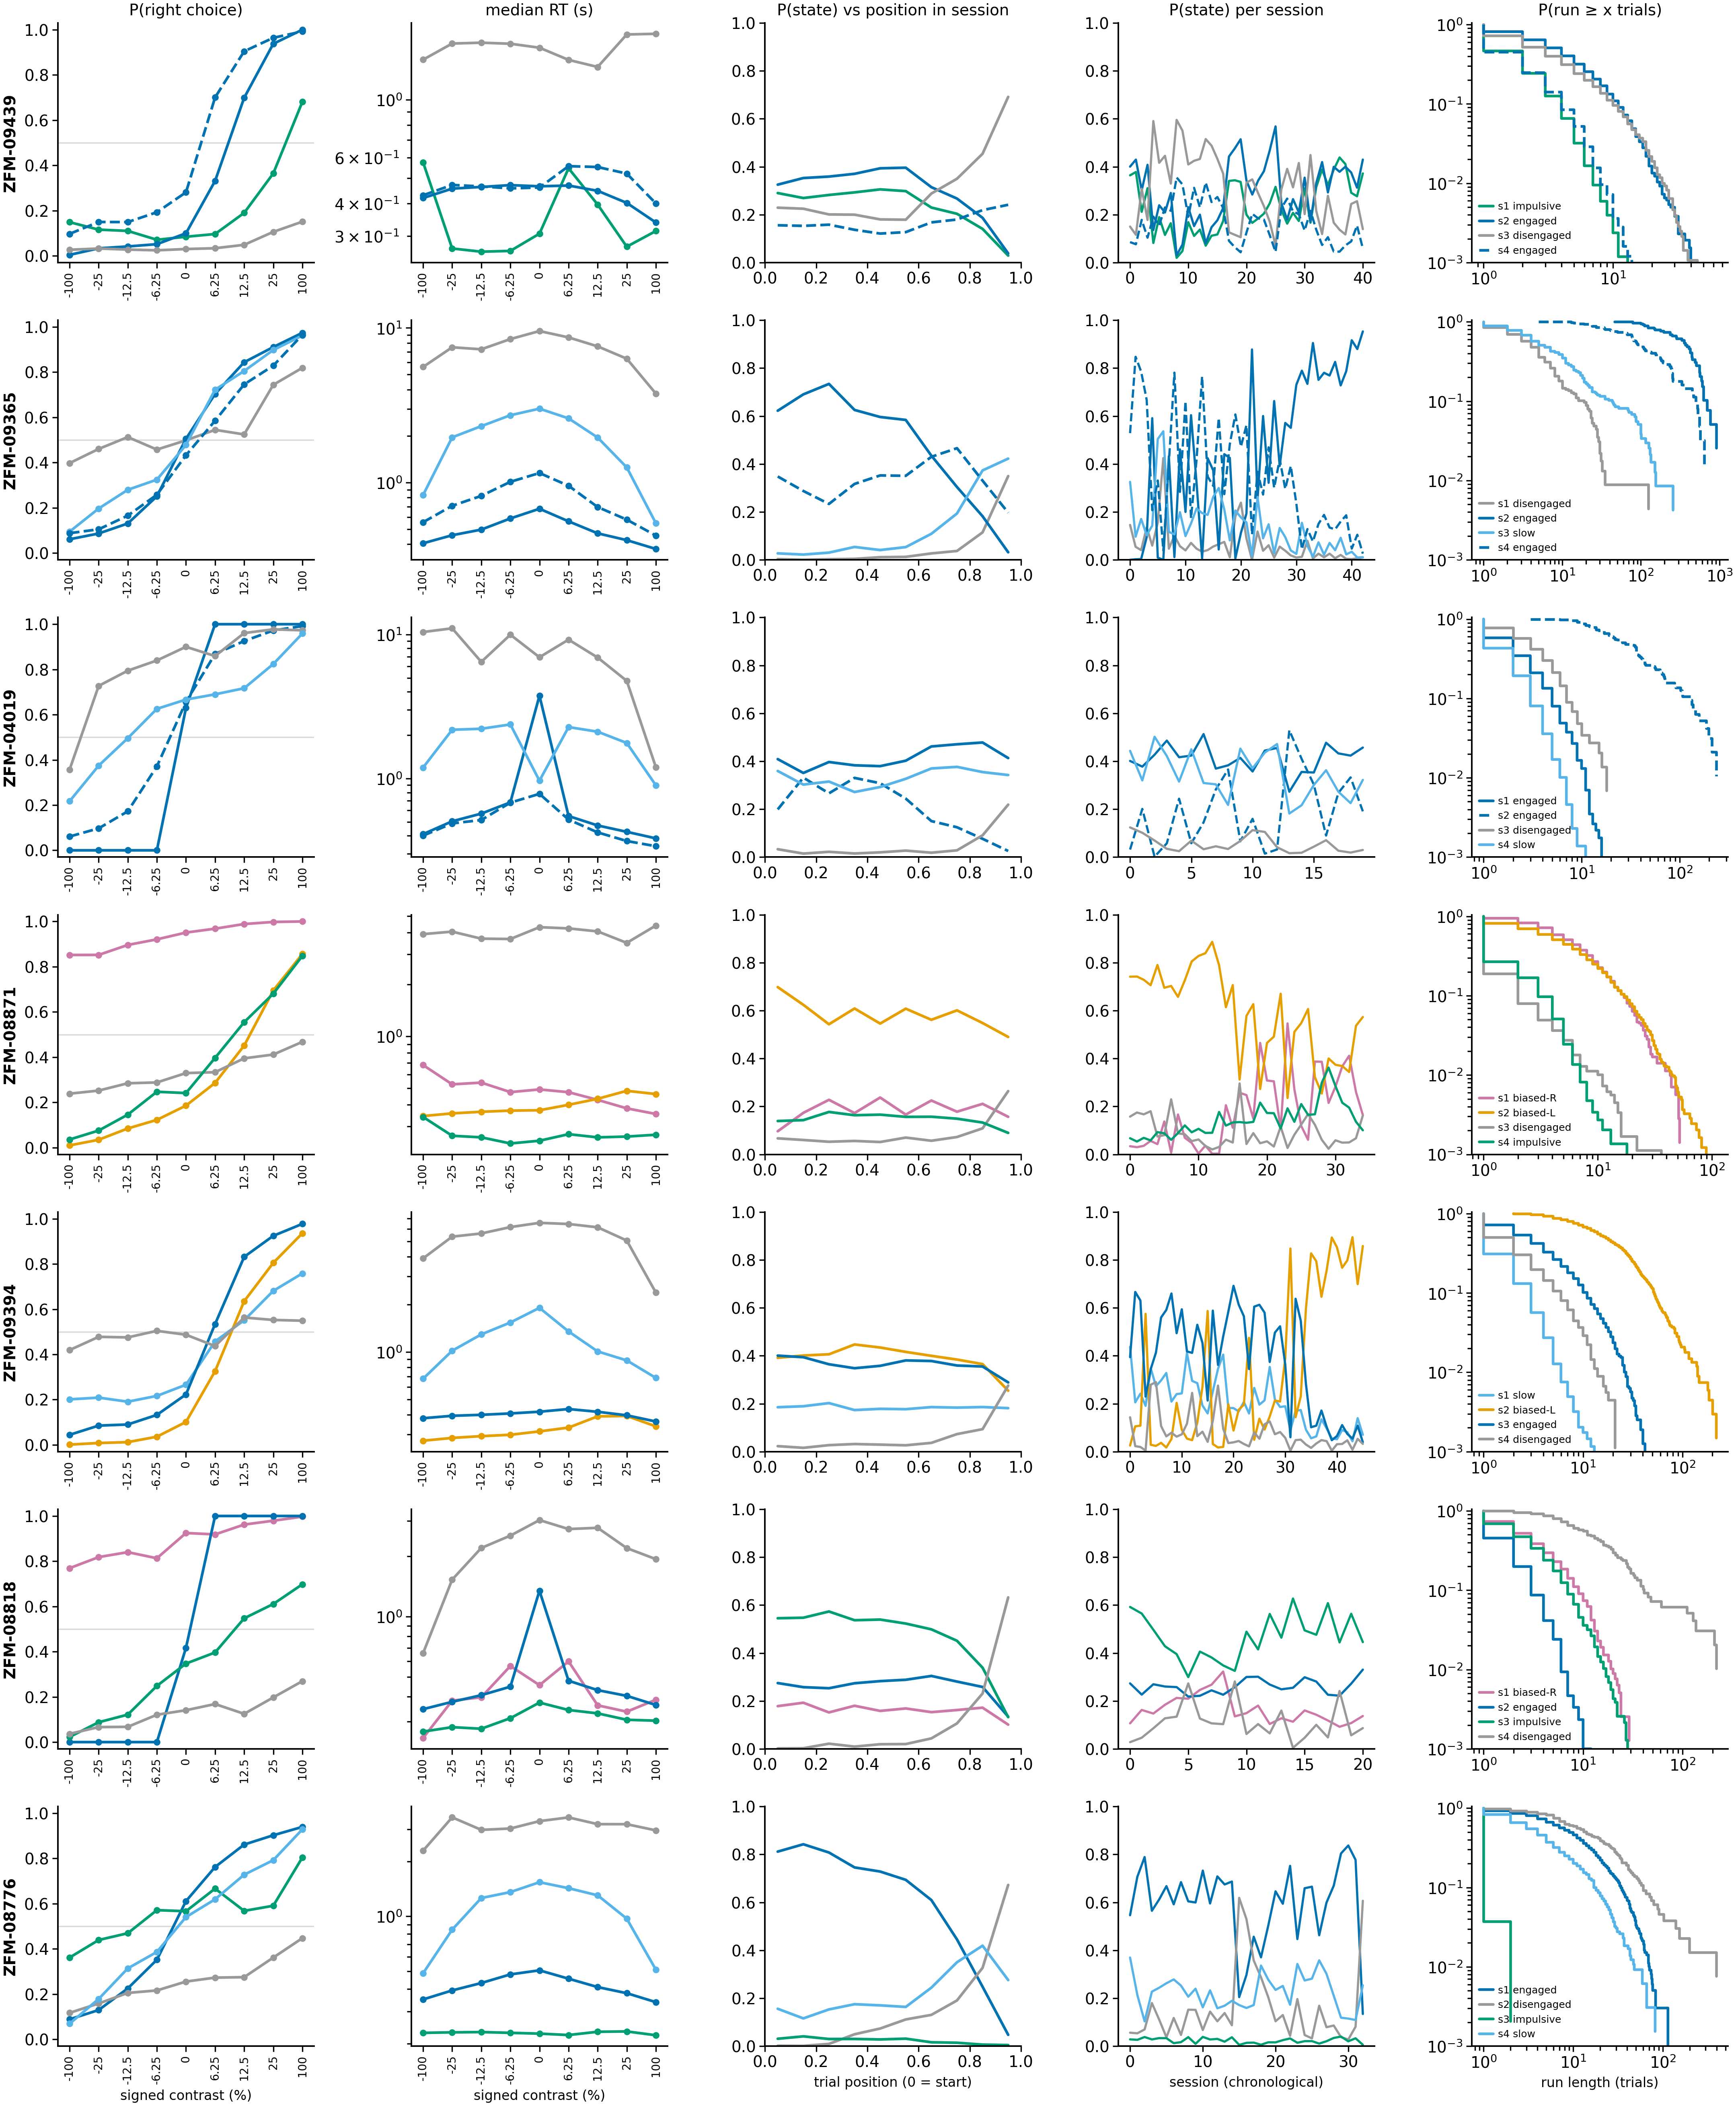

In [8]:
LEVELS = [-100, -25, -12.5, -6.25, 0, 6.25, 12.5, 25, 100]
XPOS = {c: i for i, c in enumerate(LEVELS)}
MIN_N = 10
STYLES = ['-', '--', ':', '-.']

def state_styles(m):
    s = S[S['subject'] == m].sort_values('state')
    seen, out = {}, {}
    for _, r in s.iterrows():
        i = seen.get(r['label'], 0); seen[r['label']] = i + 1
        out[r['state']] = dict(color=LABEL_COLORS[r['label']], ls=STYLES[i % 4], label=r['tag'])
    return out

fig, axes = plt.subplots(len(MICE), 5, figsize=(11, 1.9 * len(MICE)), squeeze=False)
for row, m in zip(axes, MICE):
    dm = d[d['subject'] == m].copy()
    dm['sc'] = dm['signed_contrast'].round(2).replace(-0.0, 0.0)
    sty = state_styles(m)
    for st, g in dm.groupby('state'):
        kw = dict(lw=1.2, **sty[st])
        agg = g.groupby('sc').agg(p=('choice_right', 'mean'), rt=('rt', 'median'), n=('rt', 'size'))
        agg = agg[(agg['n'] >= MIN_N) & agg.index.isin(LEVELS)]
        x = [XPOS[c] for c in agg.index]
        row[0].plot(x, agg['p'], marker='o', ms=2, **kw)
        row[1].plot(x, agg['rt'], marker='o', ms=2, **kw)
    # posteriors (all go trials of the mouse, so the curves are occupancy)
    pc = [f'p_state_{s}' for s in sorted(sty)]
    within = dm.groupby(pd.cut(dm['trial_frac'], np.linspace(0, 1, 11), include_lowest=True), observed=True)[pc].mean()
    across = dm.groupby('session_idx')[pc].mean()
    for s, c in zip(sorted(sty), pc):
        kw = {k: v for k, v in sty[s].items() if k != 'label'}
        row[2].plot(np.arange(len(within)) / 10 + 0.05, within[c], lw=1.2, **kw)
        row[3].plot(across.index, across[c], lw=1, **kw)
        L = np.sort(runs.loc[(runs['subject'] == m) & (runs['state'] == s), 'length'].to_numpy())
        if len(L):
            row[4].step(L, 1 - np.arange(len(L)) / len(L), where='post', lw=1.2, label=sty[s]['label'], **kw)
    row[0].set_ylabel(m, fontsize=7, fontweight='bold')
    row[0].set(ylim=(-0.03, 1.03)); row[0].axhline(0.5, color='0.85', lw=0.6, zorder=0)
    row[1].set(yscale='log')
    row[2].set(ylim=(0, 1), xlim=(0, 1)); row[3].set(ylim=(0, 1))
    row[4].set(xscale='log', yscale='log', ylim=(1e-3, 1.05))
    row[4].legend(fontsize=4.5, frameon=False, loc='lower left')
for ax in axes[:, :2].ravel():
    ax.set_xticks(range(len(LEVELS)), [f'{c:g}' for c in LEVELS], fontsize=5, rotation=90)
titles = ['P(right choice)', 'median RT (s)', 'P(state) vs position in session', 'P(state) per session',
          'P(run ≥ x trials)']
for ax, t in zip(axes[0], titles):
    ax.set_title(t, fontsize=7)
for ax, t in zip(axes[-1], ['signed contrast (%)', 'signed contrast (%)', 'trial position (0 = start)',
                            'session (chronological)', 'run length (trials)']):
    ax.set_xlabel(t, fontsize=6)
plt.tight_layout(); plt.show()

### Transition matrices

Each matrix gives P(state on t+1 | state on t), with rows as *from*. O is the omission state, which exists in the new format only.

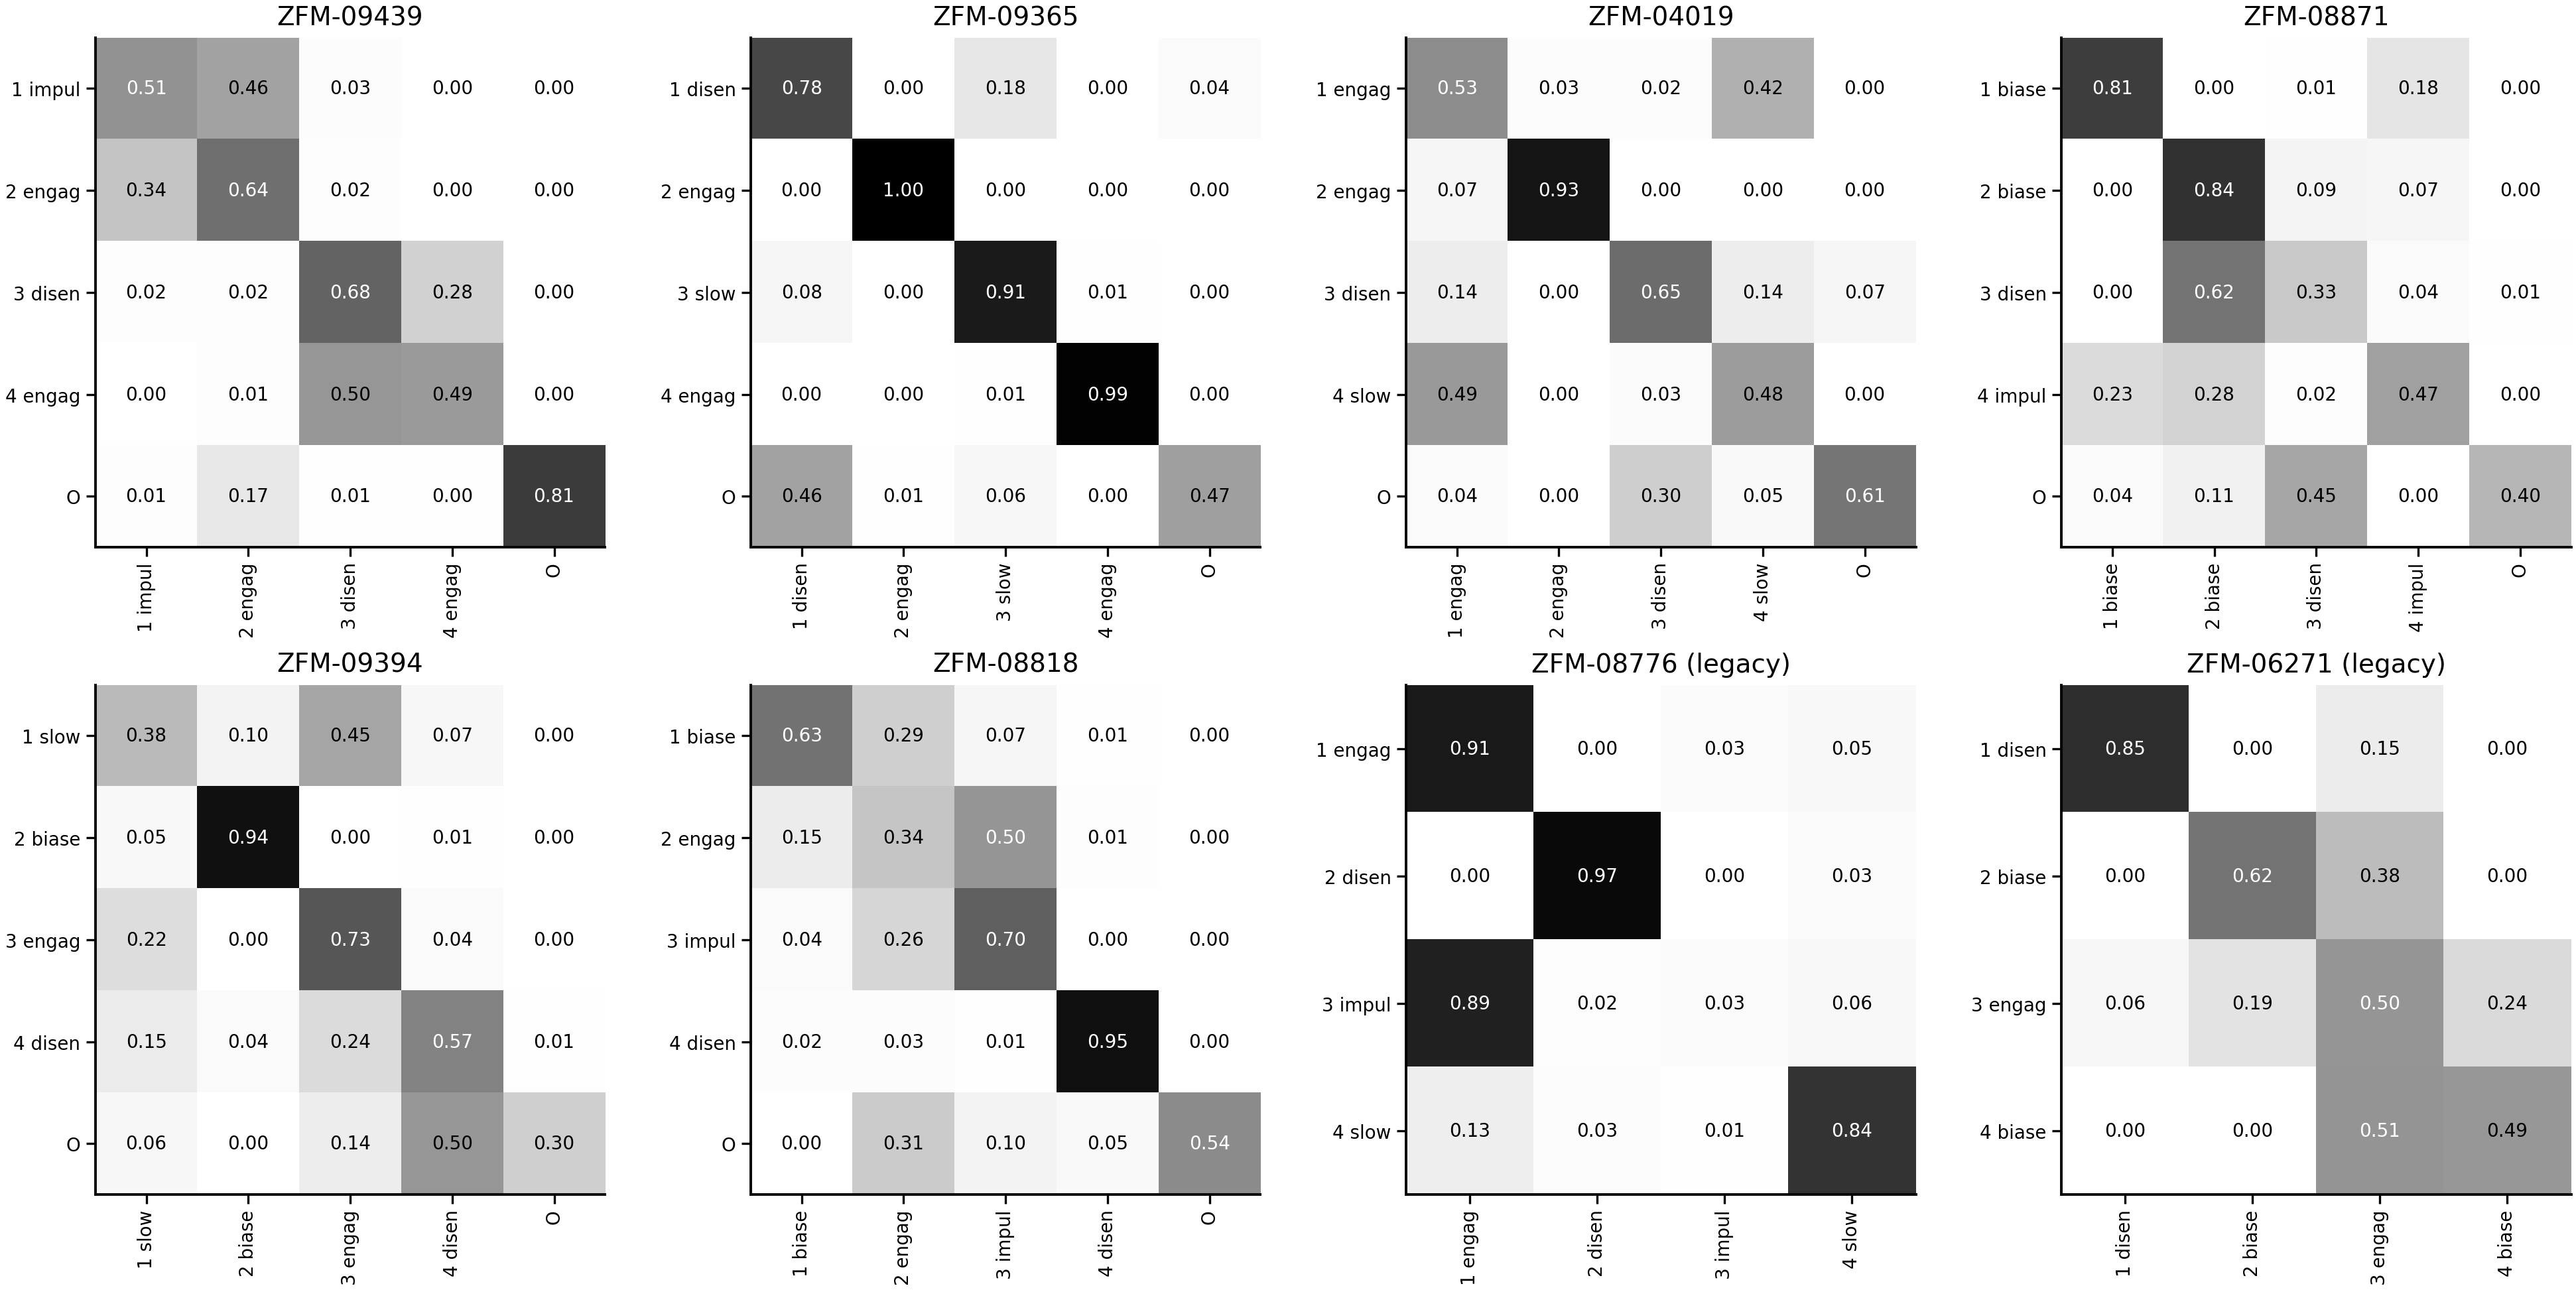

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for ax, m in zip(axes.ravel(), params['subject'].unique()):
    T = params.attrs['trans'][m]
    lab = S[S['subject'] == m].set_index('state')['label']
    ticks = [f"{s} {lab.get(s, 'O')[:5]}" if s in lab.index else 'O' for s in T.index]
    ax.imshow(T.to_numpy(), cmap='Greys', vmin=0, vmax=1)
    for i in range(len(T)):
        for j in range(len(T)):
            v = T.iat[i, j]
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=5, color='white' if v > 0.5 else 'black')
    ax.set_xticks(range(len(T)), ticks, fontsize=5, rotation=90); ax.set_yticks(range(len(T)), ticks, fontsize=5)
    ax.set_title(m + (' (legacy)' if fits.loc[m, 'format'] == 'legacy' else ''), fontsize=7)
plt.tight_layout(); plt.show()

## Are the states within-session or between-session?

Trial modes vary from trial to trial, so the mapping in step 3 depends on whether the states do too. Here we ask how much of each mouse's state sequence is explained by *which session* it is: I(state; session) / H(state). The plug-in estimate is debiased by subtracting the value obtained with session labels shuffled across trials.

In [10]:
def mi(a, b):
    ct = pd.crosstab(a, b).to_numpy().astype(float); p = ct / ct.sum()
    pa, pb = p.sum(1, keepdims=True), p.sum(0, keepdims=True)
    nz = p > 0
    return (p[nz] * np.log2(p[nz] / (pa @ pb)[nz])).sum()

def H(a):
    p = pd.Series(a).value_counts(normalize=True).to_numpy(); return -(p * np.log2(p)).sum()

rng = np.random.default_rng(0)
rows = []
for m, g in d.groupby('subject'):
    raw = mi(g['state'], g['eid'])
    null = np.mean([mi(g['state'], rng.permutation(g['eid'].to_numpy())) for _ in range(20)])
    rows.append({'subject': m, 'H(state) bits': H(g['state']), 'I(state;session)/H': (raw - null) / H(g['state']),
                 'median run (trials)': runs.loc[runs['subject'] == m, 'length'].median()})
sess = pd.DataFrame(rows).set_index('subject').round(2)
sess

,H(state) bits,I(state;session)/H,median run (trials)
subject,,,
ZFM-04019,1.74,0.09,2.0
ZFM-06271,1.70,0.00,2.0
ZFM-08776,1.44,0.11,5.0
ZFM-08818,1.83,0.04,2.0
ZFM-08871,1.49,0.15,2.0
ZFM-09365,1.64,0.29,7.0
ZFM-09394,1.69,0.28,2.0
ZFM-09439,1.86,0.11,2.0


## Summary

## Summary

- **The omission state is the no-go trials**, one-to-one (425 trials). It carries no information and is dropped.
- **There is one disengaged state in every mouse.** Drift gain is k < 0.3. Median RT is 2–7 s, the psychometric is flat and usually stuck on one side, and block has no effect. The state takes over in the last ~20% of the session. It is the clearest state that maps across mice.
- **Every mouse also has 1–2 engaged states.** They have steep psychometrics, RTs of 0.3–0.7 s, and easy accuracy of 0.9 or more. The remaining states fall into three kinds:
  - **slow** (09365·3, 08776·4, 09394·1, 04019·4): RTs of 1–2 s, shallower but structured psychometrics, bell-shaped chronometrics, and growing late in the session. These look like a halfway step toward disengagement.
  - **impulsive** (08818·3, 08871·4, 08776·3, 09439·1): RTs of about 0.2–0.4 s with errors on easy trials.
  - **biased**, which comes in two flavours. One is side perseveration: 08871·1 and 08818·1 choose right almost regardless of contrast. The other is an engaged but shifted psychometric: 08871·2 and 09394·2 are steep but left-shifted. Biased states partly follow the block prior. 08871·1 (right-biased) fills 34% of 0.2 blocks but only 6% of 0.8 blocks, and its left-biased partner shows the reverse.
- **`a0` reads directly as choice bias.** Its correlation with P(right) at 0% contrast is r = 0.92, and a0 > 0.5 means rightward.
- **Timescale: the states switch close to trial by trial.** The median Viterbi run is 2 trials in 5 of 7 mice. 09365 (5–7 trials) and 08776 are the exceptions. Which session a trial comes from explains 4–29% of state entropy. It is high for 09365 and 09394, where one state takes over the later sessions (09365 engaged·2, 09394 biased-L·2), so part of those mice's state sequence is across-session drift.
- **The posteriors are often soft.** In 09439 and 08818, only 44% of trials have a max posterior above 0.8. In step 3, the soft posteriors should be used alongside the Viterbi labels.
- **The naming is provisional.** It uses fixed thresholds on k, a0, easy accuracy and RT, applied by eye to 31 states. It is a vocabulary for comparing mice, not a fitted classifier.

**For step 3 (mapping to the trial modes)**:
- The states change from trial to trial, which suits per-trial modes. 
- Use a session-wise circular-shift null.
- Report per mouse, with the provisional labels used only to line up mice.
- Treat the disengaged/slow states, which rise late in the session, as a confound shared with any mode that also drifts within the session. Control for trial position.